# CancerVerso · V3 — U-Net 2D para segmentar hígado y tumor
**Paso 4 del plan: el modelo que cierra la historia de los datos.**

Entrada: los shards de `dataset_modelo/v2` (180,238 cortes de 256×256, separados por paciente).
Salida: una U-Net que pinta cada píxel como **fondo (0), hígado (1) o tumor (2)**, y con eso calcula el **HTB% predicho** de cada CT.

Qué hace, en orden:
1. Monta Drive y revisa la GPU.
2. **Benchmark de GPU** (corre solo, sin datos): mide cuántos cortes por segundo entrena esta GPU. Sirve para la comparación T4 vs G4.
3. Copia los shards a disco local y **verifica sus huellas MD5** contra el manifiesto.
4. Carga train y val a la RAM.
5. Define la U-Net (MONAI) y la pérdida Dice + entropía cruzada.
6. **Entrena por épocas** con precisión mixta, guarda checkpoint en Drive cada época y anota una bitácora CSV. Si Colab se desconecta, retoma desde la última época.
7. **Evalúa en test:** Dice por CT y HTB% predicho vs real.
8. Muestra cortes de ejemplo y guarda el resumen.

**Entorno:** G4 (RTX PRO 6000, 96 GB). También corre en A100, L4 o T4: el tamaño de lote se ajusta solo a la memoria de la GPU.

**Para la comparación T4 vs G4:** abre este notebook con una T4 y corre solo las secciones 1 y 2. El resultado se agrega a `stats/benchmark_gpu.csv`.

## 1. Drive, GPU y configuración

In [2]:
# ============================================================
# 1a. MONTAR DRIVE, INSTALAR MONAI Y VER LA MÁQUINA
# ============================================================
from google.colab import drive
drive.mount("/content/drive")

import subprocess
subprocess.run(["pip", "install", "-q", "monai"], check=True)

import os
import glob
import time
import json
import shutil
import hashlib
import datetime
from concurrent.futures import ThreadPoolExecutor

import numpy as np
import pandas as pd
import psutil
import torch
import monai

print("PyTorch", torch.__version__, "| MONAI", monai.__version__)
print("CPUs:", os.cpu_count(), "| RAM:", round(psutil.virtual_memory().total / 1e9, 1), "GB",
      "| disco libre:", round(shutil.disk_usage("/content").free / 1e9, 1), "GB")
if not torch.cuda.is_available():
    raise RuntimeError("No hay GPU. Entorno de ejecución -> Cambiar tipo de entorno -> GPU G4 (o A100/L4/T4).")
GPU = torch.cuda.get_device_name(0)
GPU_GB = torch.cuda.get_device_properties(0).total_memory / 1e9
print("GPU:", GPU, "|", round(GPU_GB, 1), "GB")

Mounted at /content/drive
PyTorch 2.14.1+cu130 | MONAI 1.6.2
CPUs: 8 | RAM: 54.8 GB | disco libre: 252.9 GB
GPU: Tesla T4 | 15.6 GB


In [3]:
# ============================================================
# 1b. CONFIGURACIÓN
# ============================================================
BASE = "/content/drive/MyDrive/Big data Zucco"
DIR_DATASET = BASE + "/dataset_modelo/v2"       # shards del notebook V2
DIR_STATS = BASE + "/stats"
DIR_MODELO = BASE + "/modelos/unet_v1"          # checkpoints, bitácora y resultados
LOCAL = "/content/cv_modelo"                    # copia local de los shards

SEMILLA = 42
EPOCAS = 25                 # pasadas completas por train
TIEMPO_MAX_MIN = 120        # si se pasa de este tiempo, termina la época en curso y se detiene
LR = 1e-3                   # tasa de aprendizaje inicial

# Precisión mixta: bf16 si la GPU lo soporta (G4, A100, L4); si no (T4), fp16
if torch.cuda.get_device_capability()[0] >= 8:
    PRECISION = torch.bfloat16
else:
    PRECISION = torch.float16

# Tamaño de lote según la memoria de la GPU
if GPU_GB >= 70:
    LOTE = 128              # G4 (96 GB)
elif GPU_GB >= 35:
    LOTE = 64               # A100 40 GB
else:
    LOTE = 24               # T4 / L4

os.makedirs(DIR_MODELO, exist_ok=True)
os.makedirs(LOCAL, exist_ok=True)
torch.manual_seed(SEMILLA)
np.random.seed(SEMILLA)
dispositivo = torch.device("cuda")
print("Precisión:", PRECISION, "| lote:", LOTE, "| épocas:", EPOCAS)

tiempos = []
def anotar(etapa, t0, detalle=""):
    segundos = round(time.time() - t0, 1)
    tiempos.append({"etapa": etapa, "segundos": segundos, "detalle": detalle, "gpu": GPU})
    print("Tiempo de '" + etapa + "':", segundos, "s", detalle)

Precisión: torch.float16 | lote: 24 | épocas: 25


## 2. La U-Net y el benchmark de GPU

**U-Net 2D de MONAI:** una red que primero "encoge" la imagen para entender el contexto (5 niveles: 32 → 512 filtros) y luego la "agranda" para pintar cada píxel. Entra 1 canal (el CT) y salen 3 (fondo, hígado, tumor).

**Benchmark de GPU:** entrena 30 pasos con datos inventados del mismo tamaño que los reales, en fp32 y en precisión mixta. No necesita el dataset, así que se puede correr igual en una T4 para comparar. Cada corrida se agrega a `stats/benchmark_gpu.csv`.

In [4]:
# ============================================================
# 2. MODELO Y BENCHMARK DE GPU
# ============================================================
from monai.networks.nets import UNet
from monai.losses import DiceCELoss

def nueva_unet():
    return UNet(spatial_dims=2, in_channels=1, out_channels=3,
                channels=(32, 64, 128, 256, 512), strides=(2, 2, 2, 2), num_res_units=2)

def medir_gpu(precision, lote, pasos=30):
    # Entrena 'pasos' veces con datos al azar y devuelve cortes por segundo
    modelo = nueva_unet().to(dispositivo)
    opt = torch.optim.AdamW(modelo.parameters(), lr=LR)
    perdida = DiceCELoss(to_onehot_y=True, softmax=True)
    escala = torch.amp.GradScaler(enabled=(precision == torch.float16))
    x = torch.rand(lote, 1, 256, 256, device=dispositivo)
    y = torch.randint(0, 3, (lote, 1, 256, 256), device=dispositivo)
    torch.cuda.reset_peak_memory_stats()
    for i in range(pasos + 5):
        if i == 5:                                    # los 5 primeros pasos son de calentamiento
            torch.cuda.synchronize()
            t0 = time.time()
        with torch.autocast("cuda", dtype=precision, enabled=(precision != torch.float32)):
            p = perdida(modelo(x), y)
        opt.zero_grad()
        escala.scale(p).backward()
        escala.step(opt)
        escala.update()
    torch.cuda.synchronize()
    seg = time.time() - t0
    mem = torch.cuda.max_memory_allocated() / 1e9
    del modelo, opt
    torch.cuda.empty_cache()
    return round(pasos * lote / seg), round(mem, 1)

print("Parámetros de la U-Net:", round(sum(p.numel() for p in nueva_unet().parameters()) / 1e6, 2), "millones")

filas = []
for nombre, precision in [("fp32", torch.float32), ("mixta " + str(PRECISION).split(".")[-1], PRECISION)]:
    cps, mem = medir_gpu(precision, LOTE)
    filas.append({"gpu": GPU, "gpu_gb": round(GPU_GB), "precision": nombre, "lote": LOTE,
                  "cortes_por_s": cps, "memoria_gb": mem, "fecha": datetime.datetime.now().isoformat(timespec="seconds")})
    print(nombre, "| lote", LOTE, "|", cps, "cortes/s |", mem, "GB de GPU")

bench_gpu = pd.DataFrame(filas)
ruta_bench = DIR_STATS + "/benchmark_gpu.csv"
bench_gpu.to_csv(ruta_bench, mode="a", index=False, header=not os.path.exists(ruta_bench))
cps_mixta = filas[-1]["cortes_por_s"]
print("\nUna época de train (~126,000 cortes) tardaría unos", round(126000 / cps_mixta / 60, 1), "min con precisión mixta")

Parámetros de la U-Net: 6.5 millones
fp32 | lote 24 | 148 cortes/s | 1.5 GB de GPU
mixta float16 | lote 24 | 284 cortes/s | 0.9 GB de GPU

Una época de train (~126,000 cortes) tardaría unos 7.4 min con precisión mixta


## 3. Copiar los shards y verificar las huellas
Los 90 shards (23.6 GB) se copian de Drive al disco local con 8 copias a la vez. Después se calcula la huella MD5 de cada uno y se compara con la del `manifest.json`: si un archivo se dañó en el camino, se detiene todo. **Es la prueba de que el modelo entrena exactamente con el dataset documentado.**

In [5]:
# ============================================================
# 3. COPIA A DISCO LOCAL + VERIFICACIÓN MD5 CONTRA EL MANIFIESTO
# ============================================================
with open(DIR_DATASET + "/manifest.json") as f:
    manifest = json.load(f)
print(manifest["nombre"], "| creado", manifest["creado"], "|", len(manifest["archivos"]), "shards")

def md5(ruta):
    h = hashlib.md5()
    with open(ruta, "rb") as f:
        for bloque in iter(lambda: f.read(8 * 1024 * 1024), b""):
            h.update(bloque)
    return h.hexdigest()

def copiar_y_verificar(archivo):
    origen = DIR_DATASET + "/" + archivo["archivo"]
    destino = LOCAL + "/" + archivo["archivo"]
    os.makedirs(os.path.dirname(destino), exist_ok=True)
    if not os.path.exists(destino) or os.path.getsize(destino) != os.path.getsize(origen):
        shutil.copy(origen, destino + ".tmp")
        os.rename(destino + ".tmp", destino)
    return archivo["archivo"], md5(destino) == archivo["md5"]

t0 = time.time()
with ThreadPoolExecutor(8) as pool:
    resultados = list(pool.map(copiar_y_verificar, manifest["archivos"]))
malos = [nombre for nombre, ok in resultados if not ok]
shutil.copy(DIR_DATASET + "/indice_cortes.csv", LOCAL + "/indice_cortes.csv")
gb = sum(a["mb"] for a in manifest["archivos"]) / 1000
anotar("copia + MD5 de shards", t0, str(round(gb, 2)) + " GB")
if malos:
    raise RuntimeError("Huella MD5 distinta en: " + str(malos) + ". Borra esos archivos de " + LOCAL + " y vuelve a correr.")
print("Las", len(resultados), "huellas coinciden con el manifiesto.")

CancerVerso dataset 2D hígado v2 | creado 2026-11-24T06:48:07 | 90 shards
Tiempo de 'copia + MD5 de shards': 153.7 s 23.62 GB
Las 90 huellas coinciden con el manifiesto.


## 4. Cargar train y val a la RAM
Los cortes se quedan en `uint8` en la RAM (4 veces menos que `float32`). La conversión a 0–1 se hace **en la GPU**, lote por lote.

In [6]:
# ============================================================
# 4. CARGAR TRAIN Y VAL
# ============================================================
def cargar(split):
    imagenes, etiquetas = [], []
    for ruta in sorted(glob.glob(LOCAL + "/" + split + "/shard_*.npz")):
        s = np.load(ruta)
        imagenes.append(s["img"])
        etiquetas.append(s["lbl"])
    return np.concatenate(imagenes), np.concatenate(etiquetas)

t0 = time.time()
img_train, lbl_train = cargar("train")
img_val, lbl_val = cargar("val")
anotar("carga a RAM", t0)
print("train:", img_train.shape, "| val:", img_val.shape,
      "| RAM usada:", round((img_train.nbytes + lbl_train.nbytes + img_val.nbytes + lbl_val.nbytes) / 1e9, 1), "GB",
      "| libre:", round(psutil.virtual_memory().available / 1e9, 1), "GB")

def a_gpu(img, lbl, indices):
    # Arma un lote: uint8 -> GPU -> float 0-1 con forma [lote, 1, 256, 256]
    x = torch.from_numpy(img[indices]).to(dispositivo, non_blocking=True)
    y = torch.from_numpy(lbl[indices]).to(dispositivo, non_blocking=True)
    x = x.unsqueeze(1).float() / 255
    y = y.unsqueeze(1).long()
    return x, y

Tiempo de 'carga a RAM': 91.9 s 
train: (126199, 256, 256) | val: (26671, 256, 256) | RAM usada: 20.0 GB | libre: 29.7 GB


## 5. Cómo se mide: Dice
**Dice** compara lo que pinta el modelo con lo que pintaron los expertos: `2 × (píxeles en común) ÷ (píxeles del modelo + píxeles del experto)`. Vale 1 si coinciden perfecto y 0 si no se tocan. Se calcula aparte para hígado y para tumor; el que importa es el de **tumor**, que es el difícil (menos del 1% de los píxeles).

En validación se suma todo el grupo (Dice global). En test se calcula **por CT**.

In [7]:
# ============================================================
# 5. PREDECIR UN CONJUNTO Y CONTAR PÍXELES POR CLASE
# ============================================================
@torch.no_grad()
def predecir(modelo, img, lbl, lote=256):
    # Devuelve, por corte: píxeles predichos y reales de hígado (1) y tumor (2), y los que coinciden
    modelo.eval()
    conteos = []
    for i in range(0, len(img), lote):
        idx = np.arange(i, min(i + lote, len(img)))
        x, y = a_gpu(img, lbl, idx)
        with torch.autocast("cuda", dtype=PRECISION):
            pred = modelo(x).argmax(dim=1, keepdim=True)
        fila = []
        for c in [1, 2]:
            p, r = (pred == c), (y == c)
            fila += [p.sum(dim=(1, 2, 3)), r.sum(dim=(1, 2, 3)), (p & r).sum(dim=(1, 2, 3))]
        conteos.append(torch.stack(fila, dim=1).cpu())
    modelo.train()
    return pd.DataFrame(torch.cat(conteos).numpy(),
                        columns=["pred_hig", "real_hig", "comun_hig", "pred_tum", "real_tum", "comun_tum"])

def dice(comun, pred, real):
    return 2 * comun / max(pred + real, 1)

## 6. Entrenamiento
- **Pérdida Dice + entropía cruzada:** Dice evita que el modelo "gane" pintando todo de fondo y la entropía cruzada estabiliza el inicio.
- **Optimizador AdamW** con tasa de aprendizaje que baja suave (coseno) a lo largo de las épocas.
- **Precisión mixta (bf16):** la GPU hace las cuentas con números de 16 bits donde se puede; entrena más rápido y usa menos memoria.
- **Cada época:** se barajan los cortes, se entrena, se mide Dice en val, se anota en `bitacora_entrenamiento.csv` y se guarda `ultimo.pt` en Drive. Si el Dice de tumor mejora, también `mejor.pt`.
- **Reanudable:** si `ultimo.pt` ya existe, empieza desde ahí.

In [8]:
# ============================================================
# 6. ENTRENAR
# ============================================================
modelo = nueva_unet().to(dispositivo)
optimizador = torch.optim.AdamW(modelo.parameters(), lr=LR, weight_decay=1e-4)
programa_lr = torch.optim.lr_scheduler.CosineAnnealingLR(optimizador, T_max=EPOCAS)
perdida_fn = DiceCELoss(to_onehot_y=True, softmax=True)
escala = torch.amp.GradScaler(enabled=(PRECISION == torch.float16))

RUTA_ULTIMO = DIR_MODELO + "/ultimo.pt"
RUTA_MEJOR = DIR_MODELO + "/mejor.pt"
RUTA_BITACORA = DIR_MODELO + "/bitacora_entrenamiento.csv"

epoca_inicial, mejor_dice = 0, -1.0
if os.path.exists(RUTA_ULTIMO):
    ck = torch.load(RUTA_ULTIMO, map_location=dispositivo)
    modelo.load_state_dict(ck["modelo"])
    optimizador.load_state_dict(ck["optimizador"])
    programa_lr.load_state_dict(ck["programa_lr"])
    epoca_inicial, mejor_dice = ck["epoca"] + 1, ck["mejor_dice"]
    print("Se retoma desde la época", epoca_inicial, "| mejor Dice de tumor hasta ahora:", round(mejor_dice, 4))

rng = np.random.default_rng(SEMILLA)
inicio = time.time()
for epoca in range(epoca_inicial, EPOCAS):
    t0 = time.time()
    orden = rng.permutation(len(img_train))           # barajar los cortes en cada época
    suma_perdida, pasos = 0.0, 0
    for i in range(0, len(orden) - LOTE + 1, LOTE):
        x, y = a_gpu(img_train, lbl_train, np.sort(orden[i:i + LOTE]))
        with torch.autocast("cuda", dtype=PRECISION):
            perdida = perdida_fn(modelo(x), y)
        optimizador.zero_grad(set_to_none=True)
        escala.scale(perdida).backward()
        escala.step(optimizador)
        escala.update()
        suma_perdida += perdida.item()
        pasos += 1
    programa_lr.step()
    seg_train = time.time() - t0

    # Validación: Dice global de hígado y de tumor
    c = predecir(modelo, img_val, lbl_val).sum()
    dice_hig = dice(c["comun_hig"], c["pred_hig"], c["real_hig"])
    dice_tum = dice(c["comun_tum"], c["pred_tum"], c["real_tum"])

    fila = {"epoca": epoca, "perdida_train": round(suma_perdida / pasos, 4),
            "dice_val_higado": round(dice_hig, 4), "dice_val_tumor": round(dice_tum, 4),
            "lr": round(programa_lr.get_last_lr()[0], 6), "segundos_train": round(seg_train, 1),
            "cortes_por_s": round(pasos * LOTE / seg_train), "gpu": GPU, "lote": LOTE,
            "memoria_gpu_gb": round(torch.cuda.max_memory_allocated() / 1e9, 1)}
    pd.DataFrame([fila]).to_csv(RUTA_BITACORA, mode="a", index=False, header=not os.path.exists(RUTA_BITACORA))
    print(fila)

    # Checkpoints en Drive
    if dice_tum > mejor_dice:
        mejor_dice = dice_tum
        torch.save(modelo.state_dict(), RUTA_MEJOR)
        print("  -> nuevo mejor modelo (Dice tumor", round(dice_tum, 4), ")")
    torch.save({"modelo": modelo.state_dict(), "optimizador": optimizador.state_dict(),
                "programa_lr": programa_lr.state_dict(), "epoca": epoca, "mejor_dice": mejor_dice}, RUTA_ULTIMO)

    if (time.time() - inicio) / 60 > TIEMPO_MAX_MIN:
        print("Se alcanzó el tiempo máximo (", TIEMPO_MAX_MIN, "min). Para seguir, sube EPOCAS o TIEMPO_MAX_MIN y vuelve a correr.")
        break

anotar("entrenamiento", inicio, "hasta época " + str(epoca))

{'epoca': 0, 'perdida_train': 0.3914, 'dice_val_higado': np.float64(0.9319), 'dice_val_tumor': np.float64(0.679), 'lr': 0.000996, 'segundos_train': 508.3, 'cortes_por_s': 248, 'gpu': 'Tesla T4', 'lote': 24, 'memoria_gpu_gb': 2.1}
  -> nuevo mejor modelo (Dice tumor 0.679 )
{'epoca': 1, 'perdida_train': 0.2915, 'dice_val_higado': np.float64(0.945), 'dice_val_tumor': np.float64(0.7272), 'lr': 0.000984, 'segundos_train': 506.6, 'cortes_por_s': 249, 'gpu': 'Tesla T4', 'lote': 24, 'memoria_gpu_gb': 2.1}
  -> nuevo mejor modelo (Dice tumor 0.7272 )
{'epoca': 2, 'perdida_train': 0.2758, 'dice_val_higado': np.float64(0.9486), 'dice_val_tumor': np.float64(0.7464), 'lr': 0.000965, 'segundos_train': 506.7, 'cortes_por_s': 249, 'gpu': 'Tesla T4', 'lote': 24, 'memoria_gpu_gb': 2.1}
  -> nuevo mejor modelo (Dice tumor 0.7464 )
{'epoca': 3, 'perdida_train': 0.2663, 'dice_val_higado': np.float64(0.9483), 'dice_val_tumor': np.float64(0.7446), 'lr': 0.000938, 'segundos_train': 505.1, 'cortes_por_s': 250

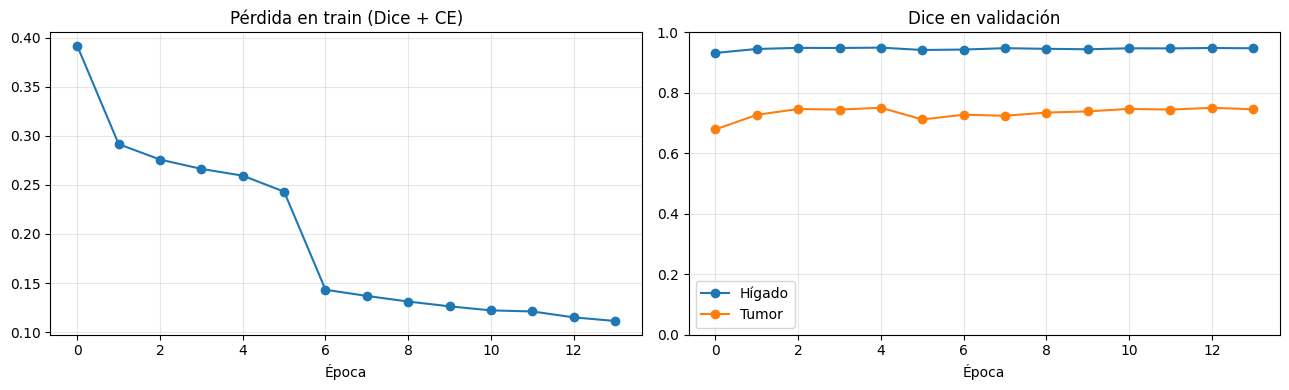

In [9]:
# ============================================================
# 6b. CURVAS DE ENTRENAMIENTO
# ============================================================
import matplotlib.pyplot as plt

bit = pd.read_csv(RUTA_BITACORA).drop_duplicates("epoca", keep="last")
fig, (e1, e2) = plt.subplots(1, 2, figsize=(13, 4))
e1.plot(bit["epoca"], bit["perdida_train"], marker="o")
e1.set_title("Pérdida en train (Dice + CE)")
e1.set_xlabel("Época")
e2.plot(bit["epoca"], bit["dice_val_higado"], marker="o", label="Hígado")
e2.plot(bit["epoca"], bit["dice_val_tumor"], marker="o", label="Tumor")
e2.set_title("Dice en validación")
e2.set_xlabel("Época")
e2.set_ylim(0, 1)
e2.legend()
for e in (e1, e2):
    e.grid(alpha=0.3)
plt.tight_layout()
fig.savefig(DIR_MODELO + "/curvas_entrenamiento.png", dpi=130)
plt.show()

## 7. Evaluación en test (pacientes que el modelo nunca vio)
Se usa `mejor.pt`. Para cada CT de test se suman sus cortes y se calcula:
- **Dice de hígado y de tumor por CT.**
- **HTB% real** (de las etiquetas) y **HTB% predicho** (de lo que pinta el modelo): `tumor ÷ (hígado + tumor) × 100`.

**Límite honesto:** el dataset 2D solo trae cortes donde los expertos/TotalSegmentator marcaron hígado. En un caso real el modelo tendría que ver todos los cortes del CT, así que estas cifras son algo optimistas.

Tiempo de 'predicción en test': 42.3 s 27368 cortes
cts_test : 346
dice_global_higado : 0.949
dice_global_tumor : 0.6531
dice_tumor_mediana_por_ct : 0.5209
dice_higado_mediana_por_ct : 0.969
htb_error_absoluto_mediano : 0.66
htb_error_absoluto_medio : 2.67
htb_correlacion : 0.8516


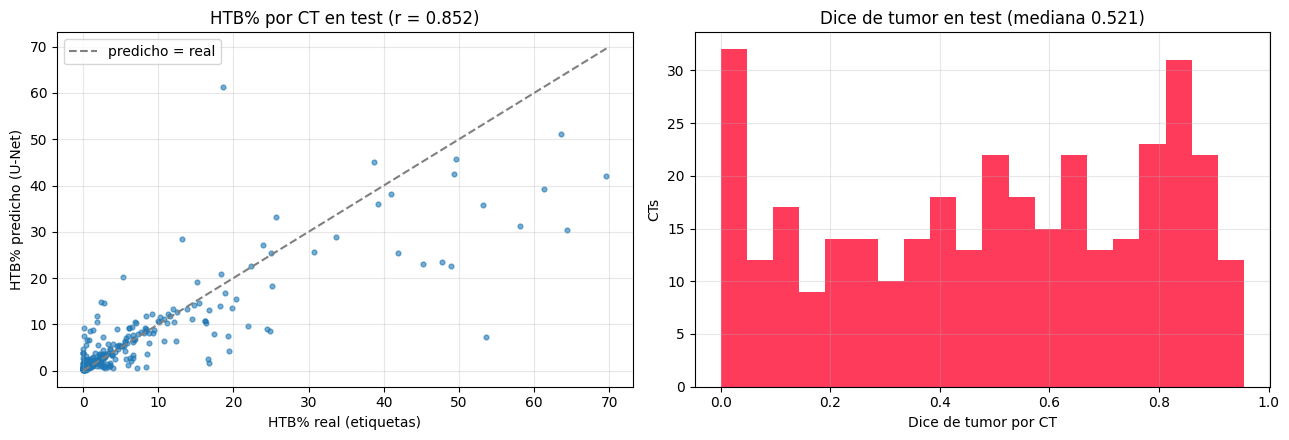

In [10]:
# ============================================================
# 7. EVALUACIÓN POR CT EN TEST
# ============================================================
del img_train, lbl_train                      # liberar RAM
img_test, lbl_test = cargar("test")
modelo.load_state_dict(torch.load(RUTA_MEJOR, map_location=dispositivo))

t0 = time.time()
conteo = predecir(modelo, img_test, lbl_test)
anotar("predicción en test", t0, str(len(img_test)) + " cortes")

indice = pd.read_csv(LOCAL + "/indice_cortes.csv")
indice_test = indice[indice["split"] == "test"].sort_values(["shard", "fila"]).reset_index(drop=True)
conteo["caso"] = indice_test["caso"].values        # mismo orden que los shards cargados

por_caso = conteo.groupby("caso").sum().reset_index()
por_caso["dice_higado"] = 2 * por_caso["comun_hig"] / (por_caso["pred_hig"] + por_caso["real_hig"]).clip(lower=1)
por_caso["dice_tumor"] = 2 * por_caso["comun_tum"] / (por_caso["pred_tum"] + por_caso["real_tum"]).clip(lower=1)
por_caso["htb_real"] = 100 * por_caso["real_tum"] / (por_caso["real_hig"] + por_caso["real_tum"]).clip(lower=1)
por_caso["htb_pred"] = 100 * por_caso["pred_tum"] / (por_caso["pred_hig"] + por_caso["pred_tum"]).clip(lower=1)
por_caso["error_htb"] = (por_caso["htb_pred"] - por_caso["htb_real"]).abs()
por_caso.round(4).to_csv(DIR_MODELO + "/test_por_caso.csv", index=False)

con_tumor = por_caso[por_caso["real_tum"] > 0]
r = np.corrcoef(por_caso["htb_real"], por_caso["htb_pred"])[0, 1]
global_ = conteo.sum()
resultados = {
    "cts_test": int(len(por_caso)),
    "dice_global_higado": round(dice(global_["comun_hig"], global_["pred_hig"], global_["real_hig"]), 4),
    "dice_global_tumor": round(dice(global_["comun_tum"], global_["pred_tum"], global_["real_tum"]), 4),
    "dice_tumor_mediana_por_ct": round(con_tumor["dice_tumor"].median(), 4),
    "dice_higado_mediana_por_ct": round(por_caso["dice_higado"].median(), 4),
    "htb_error_absoluto_mediano": round(por_caso["error_htb"].median(), 2),
    "htb_error_absoluto_medio": round(por_caso["error_htb"].mean(), 2),
    "htb_correlacion": round(r, 4),
}
for k, v in resultados.items():
    print(k, ":", v)

fig, (e1, e2) = plt.subplots(1, 2, figsize=(13, 4.5))
e1.scatter(por_caso["htb_real"], por_caso["htb_pred"], s=12, alpha=0.6)
tope = max(por_caso["htb_real"].max(), por_caso["htb_pred"].max())
e1.plot([0, tope], [0, tope], color="gray", linestyle="--", label="predicho = real")
e1.set_xlabel("HTB% real (etiquetas)")
e1.set_ylabel("HTB% predicho (U-Net)")
e1.set_title("HTB% por CT en test (r = " + str(round(r, 3)) + ")")
e1.legend()
e2.hist(con_tumor["dice_tumor"], bins=20, color="#ff3b5c")
e2.set_xlabel("Dice de tumor por CT")
e2.set_ylabel("CTs")
e2.set_title("Dice de tumor en test (mediana " + str(round(con_tumor["dice_tumor"].median(), 3)) + ")")
for e in (e1, e2):
    e.grid(alpha=0.3)
plt.tight_layout()
fig.savefig(DIR_MODELO + "/evaluacion_test.png", dpi=130)
plt.show()

## 8. Cortes de ejemplo: experto vs. U-Net

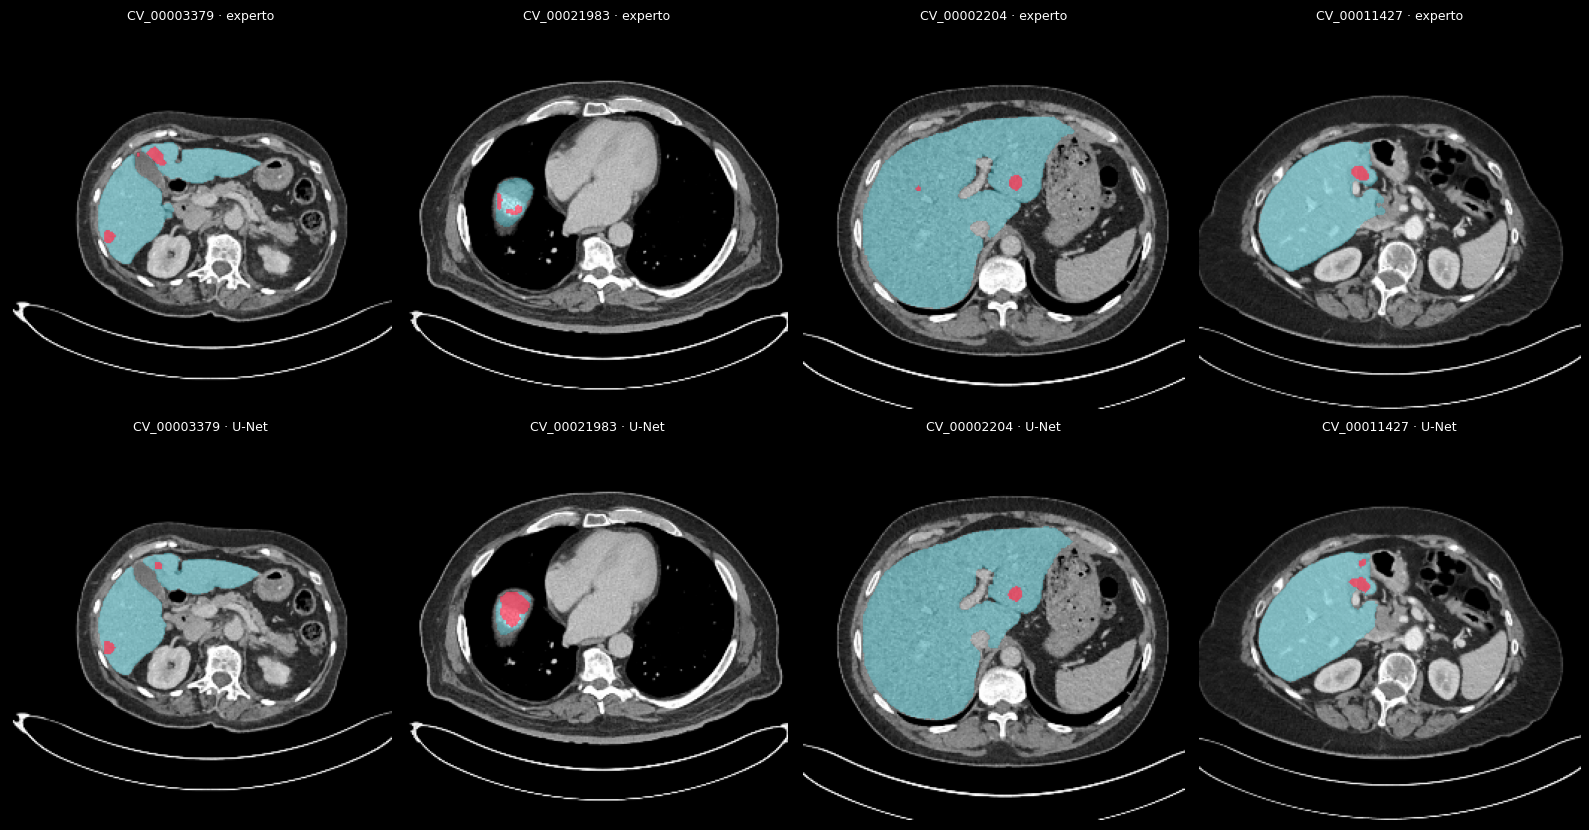

In [11]:
# ============================================================
# 8. CUATRO CORTES DE TEST CON TUMOR: ETIQUETA VS PREDICCIÓN
# ============================================================
con_tum = np.where(conteo["real_tum"].values > 0)[0]
elegidos = np.random.default_rng(SEMILLA).choice(con_tum, 4, replace=False)
x, _ = a_gpu(img_test, lbl_test, np.sort(elegidos))
with torch.no_grad(), torch.autocast("cuda", dtype=PRECISION):
    pred = modelo.eval()(x).argmax(dim=1).cpu().numpy()

def capa(etiqueta):
    c = np.zeros(etiqueta.shape + (4,))
    c[etiqueta == 1] = (0.0, 0.9, 1.0, 0.25)
    c[etiqueta == 2] = (1.0, 0.23, 0.36, 0.7)
    return c

fig, ejes = plt.subplots(2, 4, figsize=(16, 8.5), facecolor="black")
for j, k in enumerate(np.sort(elegidos)):
    for fila, (titulo, etiqueta) in enumerate([("experto", lbl_test[k]), ("U-Net", pred[j])]):
        eje = ejes[fila, j]
        eje.imshow(img_test[k], cmap="gray", vmin=0, vmax=255)
        eje.imshow(capa(etiqueta))
        eje.set_title(indice_test.loc[k, "caso"] + " · " + titulo, color="white", fontsize=9)
        eje.axis("off")
plt.tight_layout()
fig.savefig(DIR_MODELO + "/ejemplos_test.png", dpi=110)
plt.show()

## 9. Resumen

In [12]:
# ============================================================
# 9. RESUMEN Y ARCHIVOS
# ============================================================
resumen = {
    "modelo": "MONAI UNet 2D, canales (32, 64, 128, 256, 512), 2 unidades residuales",
    "dataset": manifest["nombre"], "dataset_creado": manifest["creado"],
    "gpu": GPU, "precision": str(PRECISION), "lote": LOTE,
    "epocas_entrenadas": int(pd.read_csv(RUTA_BITACORA)["epoca"].max() + 1),
    "mejor_dice_val_tumor": round(mejor_dice, 4),
    "test": resultados,
    "tiempos": tiempos,
    "creado": datetime.datetime.now().isoformat(timespec="seconds"),
}
with open(DIR_MODELO + "/resumen.json", "w") as f:
    json.dump(resumen, f, indent=2, ensure_ascii=False)
pd.DataFrame(tiempos).to_csv(DIR_MODELO + "/bitacora_tiempos.csv", index=False)

print(json.dumps(resumen, indent=2, ensure_ascii=False))
print("\nArchivos en", DIR_MODELO, ":")
for nombre in sorted(os.listdir(DIR_MODELO)):
    print(" ", nombre, "|", round(os.path.getsize(DIR_MODELO + "/" + nombre) / 1e6, 2), "MB")

{
  "modelo": "MONAI UNet 2D, canales (32, 64, 128, 256, 512), 2 unidades residuales",
  "dataset": "CancerVerso dataset 2D hígado v2",
  "dataset_creado": "2026-11-24T06:48:07",
  "gpu": "Tesla T4",
  "precision": "torch.float16",
  "lote": 24,
  "epocas_entrenadas": 14,
  "mejor_dice_val_tumor": 0.7506,
  "test": {
    "cts_test": 346,
    "dice_global_higado": 0.949,
    "dice_global_tumor": 0.6531,
    "dice_tumor_mediana_por_ct": 0.5209,
    "dice_higado_mediana_por_ct": 0.969,
    "htb_error_absoluto_mediano": 0.66,
    "htb_error_absoluto_medio": 2.67,
    "htb_correlacion": 0.8516
  },
  "tiempos": [
    {
      "etapa": "copia + MD5 de shards",
      "segundos": 153.7,
      "detalle": "23.62 GB",
      "gpu": "Tesla T4"
    },
    {
      "etapa": "carga a RAM",
      "segundos": 91.9,
      "detalle": "",
      "gpu": "Tesla T4"
    },
    {
      "etapa": "entrenamiento",
      "segundos": 7498.3,
      "detalle": "hasta época 13",
      "gpu": "Tesla T4"
    },
    {
     